# Task 2 — Content Type Analysis Dashboard

Analyze the distribution of Movies and TV Shows available in the Netflix dataset.

**Project:** Auspify Technologies — Data Analysis Using Python Internship  
**Dataset:** Netflix catalogue CSV supplied for this internship  
**Tools:** Python, Pandas, NumPy, Matplotlib, Seaborn


### Import the libraries

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

### 1. Load the cleaned_dataset

In [2]:
df = pd.read_csv("netflix_cleaned.csv")
print("Loaded cleaned dataset:", df.shape)
display(df.head())

Loaded cleaned dataset: (8790, 10)


,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,2021-09-25,2020,PG-13,90 min,Documentaries
1,s3,Tv Show,Ganglands,Julien Leclercq,France,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,Tv Show,Midnight Mass,Mike Flanagan,United States,2021-09-24,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,2021-09-22,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,2021-09-24,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"


## 2. Calculate counts and percentages
`value_counts()` counts titles in each type; normalized counts give each type's share of all records.

In [3]:
content_counts = df["type"].value_counts()
content_percentages = df["type"].value_counts(normalize=True).mul(100)

content_summary = pd.DataFrame({
    "title_count": content_counts,
    "percentage": content_percentages.round(2)
})
display(content_summary)
content_summary.to_csv("task2_content_summary.csv")

,title_count,percentage
type,,
Movie,6126,69.69
Tv Show,2664,30.31


## 3. Bar chart of title counts

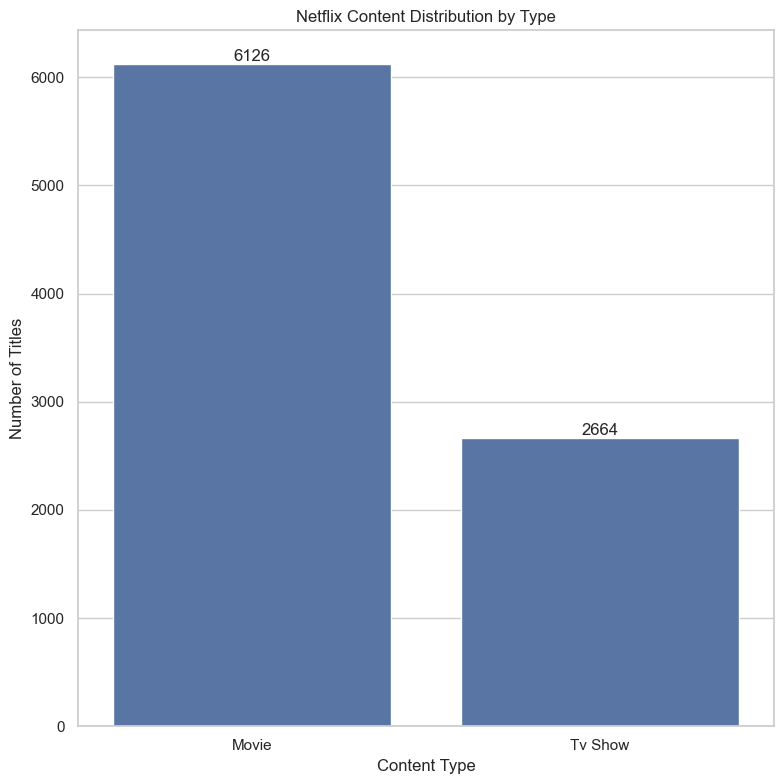

In [4]:
plt.figure(figsize=(8, 8))

ax = sns.barplot(
    x=content_counts.index,
    y=content_counts.values
)

ax.bar_label(ax.containers[0], fmt="%.0f")

plt.title("Netflix Content Distribution by Type")
plt.xlabel("Content Type")
plt.ylabel("Number of Titles")

plt.tight_layout()
plt.savefig("task2_bar_chart.png", dpi=300)
plt.show()

## 4. Pie chart of proportions

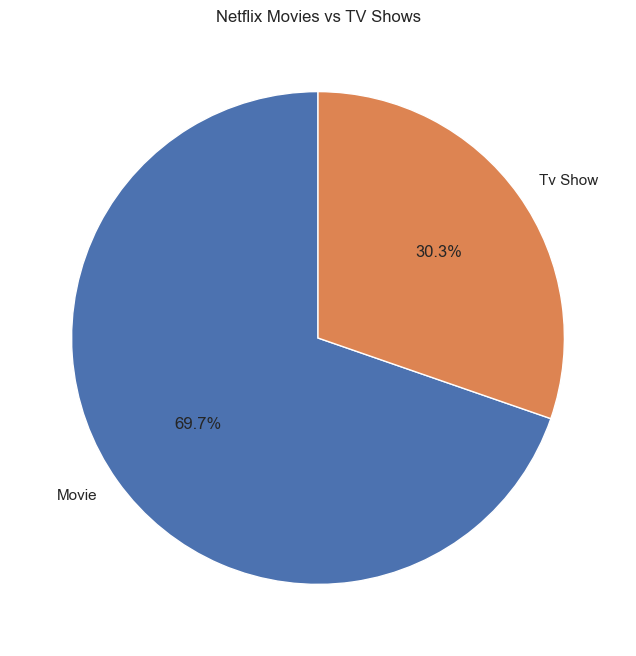

In [5]:
plt.figure(figsize=(8, 8))

plt.pie(
    content_counts.values,
    labels=content_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Netflix Movies vs TV Shows")
plt.savefig("task2_pie_chart.png", dpi=300)
plt.show()

## 5. Findings
Use the calculated table and charts to report which content type is more common and its percentage. Do not interpret catalogue counts as viewing popularity; this dataset contains no viewership measures.